In [34]:
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori,association_rules
from mlxtend.preprocessing import TransactionEncoder
import networkx as nx
%matplotlib inline

In [40]:
# items present in customer basket

dataset =[
    ['milk','bread','eggs'],
    ['milk','bread'],
    ['milk','eggs'],
    ['bread','eggs'],
    ['milk','bread','butter'],
]




In [41]:
#Convert one hot encoding (convert transaction in to boolean dataframe)
te =TransactionEncoder()

te_ary = te.fit(dataset).transform(dataset)
print(f'te :{te}')
print(f'te columents : {te.columns_}')
print(f'te_ary  : {te_ary}')
df = pd.DataFrame(te_ary,columns=te.columns_)
df

te :TransactionEncoder()
te columents : ['bread', 'butter', 'eggs', 'milk']
te_ary  : [[ True False  True  True]
 [ True False False  True]
 [False False  True  True]
 [ True False  True False]
 [ True  True False  True]]


,bread,butter,eggs,milk
0,True,False,True,True
1,True,False,False,True
2,False,False,True,True
3,True,False,True,False
4,True,True,False,True


In [42]:
sum(dataset,[])  #sum ao dataset values appendded and put in empty array next to it

['milk',
 'bread',
 'eggs',
 'milk',
 'bread',
 'milk',
 'eggs',
 'bread',
 'eggs',
 'milk',
 'bread',
 'butter']

In [43]:
set(sum(dataset,[]))  #unique item names in all the baskets
#second parameter is empty [] we are telling we are specifying the individual elements in dataset is a list

{'bread', 'butter', 'eggs', 'milk'}

Above funtionality can also be achieved with below technique used by rahul sir  without using transaction encoder 

Convert to one-hot encoding (Convert the Transaction in to boolean Dataframe)
each row in dataset is transaction and each column is item

In [17]:
for item in set(sum(dataset,[])):
    print(item)

milk
eggs
bread
butter


In [ ]:
[for item in set(sum(dataset,[]))]

In [44]:
                {item : (item in transaction)   for item in  set(sum(dataset,[]) )} for transaction in dataset

SyntaxError: invalid syntax (2453612928.py, line 1)

In [20]:
 item: (item in transaction) for item in set(sum(dataset,[])) 

SyntaxError: invalid syntax (500406076.py, line 1)

In [45]:
df = pd.DataFrame(
[
   {item : (item in transaction) for item in set(sum(dataset,[])) } for transaction in dataset
])
df

,milk,eggs,bread,butter
0,True,True,True,False
1,True,False,True,False
2,True,True,False,False
3,False,True,True,False
4,True,False,True,True


In [46]:
# find frequently occuring items combination of itemsets
frequent_itemsets =apriori(df,min_support=0.4,use_colnames=True)  # min_support =0.4 means only keep items which appears together in atleaset 40% of transactions. 
frequent_itemsets

,support,itemsets
0,0.8,(milk)
1,0.6,(eggs)
2,0.8,(bread)
3,0.4,"(milk, eggs)"
4,0.6,"(milk, bread)"
5,0.4,"(eggs, bread)"


Association unsupervised learning  is used in Market Basket Analysis(MBA, also used in Recommendation System.
Association between features  if x them y .
lift is correlatin between two variables.
lift quantitative associattion---------> is correlation
confidence is qualitative associateion-----what does is it mean ? how confident it is they appear together.

In [47]:
#Generate association rules(e.g if eggs then bread)
rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5) #min_threshole of 0.5 means only keep items which appears togehter atleaset in 50% of transactions
rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(milk),(eggs),0.8,0.6,0.4,0.500000,0.833333,1.0,-0.08,0.8,-0.500000,0.4,-0.250000,0.583333
1,(eggs),(milk),0.6,0.8,0.4,0.666667,0.833333,1.0,-0.08,0.6,-0.333333,0.4,-0.666667,0.583333
2,(milk),(bread),0.8,0.8,0.6,0.750000,0.937500,1.0,-0.04,0.8,-0.250000,0.6,-0.250000,0.750000
3,(bread),(milk),0.8,0.8,0.6,0.750000,0.937500,1.0,-0.04,0.8,-0.250000,0.6,-0.250000,0.750000
4,(eggs),(bread),0.6,0.8,0.4,0.666667,0.833333,1.0,-0.08,0.6,-0.333333,0.4,-0.666667,0.583333
5,(bread),(eggs),0.8,0.6,0.4,0.500000,0.833333,1.0,-0.08,0.8,-0.500000,0.4,-0.250000,0.583333


correlation is a measure of linear relationship between two variables
covariance has no fixed value --mean covariance can be positive or negative
in positive covariance if one variable  goes up other variable goes up
in negative covariance if one variable  goes up other variable goes down

# lift in above score is correlation
if correlation is greater than 0 it is positive correlation
if correlation is less than 0 it is negative correlation



In [48]:
print(rules[['antecedents','consequents','confidence','lift']])

  antecedents consequents  confidence      lift
0      (milk)      (eggs)    0.500000  0.833333
1      (eggs)      (milk)    0.666667  0.833333
2      (milk)     (bread)    0.750000  0.937500
3     (bread)      (milk)    0.750000  0.937500
4      (eggs)     (bread)    0.666667  0.833333
5     (bread)      (eggs)    0.500000  0.833333


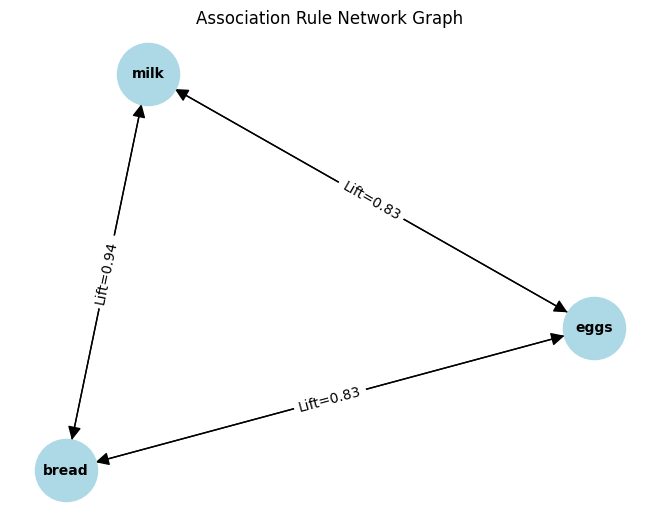

In [49]:
#Create a graph  Di Graph is Directed Graph,Associationn rules as nodes in network
g = nx.DiGraph()  #Directed Graph
#Add edges to the graph
for _, row in rules.iterrows():
    g.add_edge(','.join(list(row['antecedents'])),
          ','.join(list(row['consequents'])), weight=row['lift']  )
# rules.iterrow returns current row number and series of object representing each row.----------join is used to convert immutable set --frozen set to string    
pos = nx.spring_layout(g,k=0.5,seed=42)
# Draw nodes and edges
nx.draw(g, pos, with_labels=True, node_size=2000, node_color='lightblue', 
        font_size=10, font_weight='bold', arrowsize=20)
labels = nx.get_edge_attributes(g, 'weight')
nx.draw_networkx_edge_labels(g, pos, edge_labels={k: f"Lift={v:.2f}" for k,v in labels.items()})

plt.title('Association Rule Network Graph')
plt.show()

Adding edges with lift as weight

In [ ]:
for _,row in rules.iterrows():
    source=','.join(list(row['antecedents']))
    target =','.join(list(row['consequents']))
    lift = row['lift']
    g.add_edge(source,target,lift=lift)



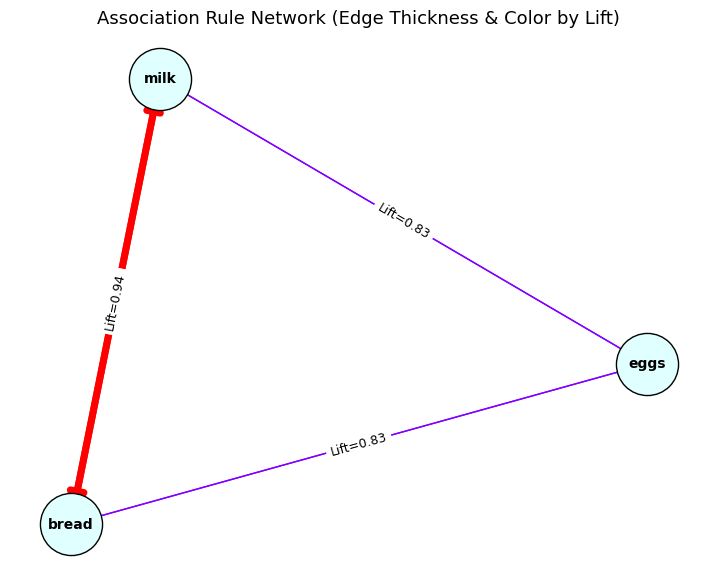

In [54]:
#Visualize the Graph
plt.figure(figsize=(9,7))
pos =nx.spring_layout(g,k=0.5,seed=42)
#Extract lift values
edges=g.edges(data=True)
weights=[d['weight'] for (_,_,d) in edges]
# Normalize lift values for visual scaling
max_weight = max(weights)
min_weight = min(weights)
normalized_weights = [(w - min_weight) / (max_weight - min_weight + 1e-9) * 4 + 1 for w in weights]  # thickness
colors = [plt.cm.rainbow((w - min_weight) / (max_weight - min_weight + 1e-9)) for w in weights]       # color gradient 

#VIBGYOR = ['Violet', 'Indigo', 'Blue', 'Green', 'Yellow', 'Orange', 'Red']

# Draw nodes and edges
nx.draw_networkx_nodes(g, pos, node_size=2000, node_color='lightcyan', edgecolors='black')
nx.draw_networkx_labels(g, pos, font_size=10, font_weight='bold')
nx.draw_networkx_edges(g, pos, edgelist=g.edges(), width=normalized_weights, edge_color=colors, arrowsize=25)
nx.draw_networkx_edge_labels(g, pos, 
                             edge_labels={(u, v): f"Lift={d['weight']:.2f}" for u, v, d in g.edges(data=True)},
                             font_size=9)

plt.title("Association Rule Network (Edge Thickness & Color by Lift)", fontsize=13)
plt.axis('off')
plt.show()
